<a href="https://colab.research.google.com/github/abekpudo/my-ml-zoomcamp/blob/main/Module_3_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
# Importing needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer

import warnings
warnings.filterwarnings('ignore')

In [3]:
# Fetching the data
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

!wget $data -O lead_scoring.csv

--2026-10-17 18:46:24--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘lead_scoring.csv’

lead_scoring.csv    100%[===================>] 272.21K  --.-KB/s    in 0.03s   

2026-10-17 18:46:25 (10.1 MB/s) - ‘lead_scoring.csv’ saved [278746/278746]



In [4]:
# Displaying the data
ls = pd.read_csv('lead_scoring.csv')
ls.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
# Check for missing values
ls.isnull().sum()

,0
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


In [7]:
# Displaying the column data types
ls.dtypes

,0
lead_source,object
industry,object
employment_status,object
location,object
annual_income,float64
number_of_courses_viewed,int64
interaction_count,int64
lead_score,float64
converted,int64


In [18]:
# Filling missing values ('NA' for categorical columns and 0.0 for numerical columns)
for col in ls.columns:
    if ls[col].dtype == 'object':
        ls[col].fillna('NA', inplace=True)
    else:
        ls[col].fillna(0.0, inplace=True)

In [14]:
# Confirm missing values operations
ls.isnull().sum()

,0
lead_source,0
industry,0
employment_status,0
location,0
annual_income,0
number_of_courses_viewed,0
interaction_count,0
lead_score,0
converted,0


In [19]:
# Q1. Most frequent observation (mode) for the column 'industry'
industry_mode = ls['industry'].mode()[0]
print(f"The mode for the column 'industry' is: {industry_mode}")

The mode for the column 'industry' is: technology


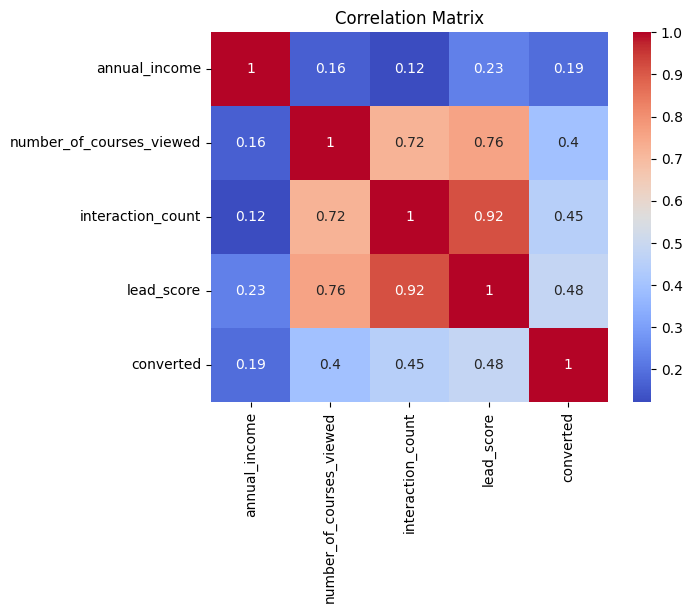

In [22]:
# Q2. Correlation matrix for numerical columns
corr_matrix = ls.select_dtypes(include=['float64', 'int64']).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [27]:
# Split the data
ls_full_train, ls_test = train_test_split(ls, test_size=0.2, random_state=42)
ls_train, ls_val = train_test_split(
    ls_full_train, test_size=0.25, random_state=42
)

len(ls_train), len(ls_val), len(ls_test)

(3000, 1000, 1000)

In [30]:
#  Separate the target column
y_train_full = ls_full_train.converted.values
y_train = ls_train.converted.values
y_test = ls_test.converted.values
y_val = ls_val.converted.values

del ls_full_train['converted']
del ls_train['converted']
del ls_val['converted']
del ls_test['converted']

In [32]:
# Q3. Mutual information score between converted and other categorical variables
train_categorical = ls_train.select_dtypes(include=['object', 'bool'])
mi = train_categorical.apply(lambda s: mutual_info_score(s, y_train))
mi.sort_values(ascending=False)

,0
lead_source,0.034346
employment_status,0.018966
industry,0.001995
location,0.001043


In [35]:
# Q4. Training a Logistic regression model

# Create One-Hot Encoding with DictVectorizer
dv = DictVectorizer(sparse=False)

train_dict = ls_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

# Train the model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

model.fit(X_train, y_train)
print("The model has been trained!\n")

# Evaluate the model
val_dict = ls_val.to_dict(orient='records')
X_val = dv.transform(val_dict)
y_pred = model.predict(X_val)

accuracy = accuracy_score(y_val, y_pred)
print(f"Model accuracy on validation dataset: {accuracy:.2f}")

The model has been trained!

Model accuracy on validation dataset: 0.65


In [36]:
# Q5. Finding the least useful feature using the feature elimination technique

features = ls_train.columns.tolist()
feature_elim_scores = []

for feature in features:
    train_dict = ls_train.drop(feature, axis=1).to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    val_dict = ls_val.drop(feature, axis=1).to_dict(orient='records')
    X_val = dv.transform(val_dict)
    y_pred = model.predict(X_val)
    score = accuracy_score(y_val, y_pred)
    diff = accuracy - score
    feature_elim_scores.append((feature, score, diff))

feature_elim_scores

[('lead_source', 0.642, 0.0030000000000000027),
 ('industry', 0.645, 0.0),
 ('employment_status', 0.645, 0.0),
 ('location', 0.645, 0.0),
 ('annual_income', 0.724, -0.07899999999999996),
 ('number_of_courses_viewed', 0.643, 0.0020000000000000018),
 ('interaction_count', 0.601, 0.04400000000000004),
 ('lead_score', 0.644, 0.0010000000000000009)]

In [51]:
# Q6. Training regularized models using various values of C
train_dict = ls_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = ls_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

reg_values = [0.000001, 0.00001, 0.0001, 0.001]

for c in reg_values:
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)
    accuracy = accuracy_score(y_val, y_pred)
    print(f"Model accuracy for C={c}: {accuracy:.2f}")


Model accuracy for C=1e-06: 0.60
Model accuracy for C=1e-05: 0.60
Model accuracy for C=0.0001: 0.61
Model accuracy for C=0.001: 0.65
